### Imports & loading data


In [ ]:
import torch
import matplotlib.pyplot as plt
import numpy as np
from transformers import TFAutoModelForSequenceClassification, AutoTokenizer
from transformers_interpret import SequenceClassificationExplainer
import shap
import tensorflow as tf
import numpy as np
from transformers import pipeline
import seaborn as sns

In [ ]:


STARTING_MODEL_NAME = "xlm-roberta-base"
local_model_path = "./model"

tokenizer = AutoTokenizer.from_pretrained(STARTING_MODEL_NAME)

model = TFAutoModelForSequenceClassification.from_pretrained(
    local_model_path, num_labels=7)
model.summary()

TensorFlow and JAX classes are deprecated and will be removed in Transformers v5. We recommend migrating to PyTorch classes or pinning your version of Transformers.
All model checkpoint layers were used when initializing TFXLMRobertaForSequenceClassification.

All the layers of TFXLMRobertaForSequenceClassification were initialized from the model checkpoint at ./model.
If your task is similar to the task the model of the checkpoint was trained on, you can already use TFXLMRobertaForSequenceClassification for predictions without further training.


Model: "tfxlm_roberta_for_sequence_classification"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 roberta (TFXLMRobertaMainL  multiple                  277453056 
 ayer)                                                           
                                                                 
 classifier (TFXLMRobertaCl  multiple                  595975    
 assificationHead)                                               
                                                                 
Total params: 278049031 (1.04 GB)
Trainable params: 278049031 (1.04 GB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


# model_wrapper

It is a thin adapter between your text classification model and explainability tools (SHAP in this case). SHAP expects a callable that:

- Takes raw texts as input.

-> Returns numeric model outputs (logits or probabilities) as a NumPy array.

This function does exactly that.


In [ ]:

def model_wrapper(texts):
    """
    This function takes a list of texts, tokenizes them,
    and returns the model's logits as a NumPy array.
    """
    # Convert the input to a list of strings
    texts = list(texts)

    # Tokenize the input texts
    inputs = tokenizer(texts, return_tensors="tf",
                       padding=True, truncation=True, max_length=512)

    # Move tensors to the same device as the model (important for GPU)
    # inputs = {k: v.to(model.device) for k, v in inputs.items()}

    # Get model output
    with torch.no_grad():
        outputs = model(inputs)

    # Extract logits and convert to a detached NumPy array
    return outputs.logits.numpy()

# Create a SHAP explainer using the WRAPPER FUNCTION
# Note: We pass `model_wrapper` instead of the raw `model`


class_names = list(model.config.id2label.values())
print(class_names)
print(f"Detected Class Names: {class_names}")


explainer = shap.Explainer(model_wrapper, tokenizer)

# 4. Define the text to be explained and get SHAP values
# Bulgarian for "I am so happy to see you!"
text = ["Много се радвам да те видя, независимо от предишните ни разговори."]
shap_values = explainer(text)

# 5. Visualize the explanation for the first input

# IMPROVED SHAP VISUALIZATION
# Assuming your model's config has id2label mapping
labels = model.config.id2label
print(labels)
# Get SHAP values (same as before)
shap_values = explainer(text)

# Visualize the explanation for a SPECIFIC emotion, e.g., 'joy' (assuming it's label 4)
joy_label_index = 4
shap.plots.text(shap_values[0, :, joy_label_index])

# Or create a dropdown to select which emotion to explain (more advanced)

labels = [
    'neutral',
    'sadness',
    'fear',
    'happiness',
    'anger',
    'disgust',
    'surprise'
]

['neutral', 'sadness', 'fear', 'happiness', 'anger', 'disgust', 'surprise']
Detected Class Names: ['neutral', 'sadness', 'fear', 'happiness', 'anger', 'disgust', 'surprise']


  0%|          | 0/272 [00:00<?, ?it/s]

PartitionExplainer explainer: 2it [00:14, 14.62s/it]               


{0: 'neutral', 1: 'sadness', 2: 'fear', 3: 'happiness', 4: 'anger', 5: 'disgust', 6: 'surprise'}


  0%|          | 0/272 [00:00<?, ?it/s]

PartitionExplainer explainer: 2it [00:14, 14.09s/it]               


## Gradient x Input

- Gradient: how much the output changes if you nudge each input dimension.

- × Input: scaled by the embedding value itself.

This gives a per-embedding-dimension relevance score for each token.

### Why we use it

- This is a fine-grained attribution method that tells you which tokens and embedding dimensions contributed most to the final prediction. Later you can sum over embedding_dim if you want one score per token.


In [ ]:


# Make sure your function definition is exactly this one
def gradient_x_input(model, inputs):
    """
    Calculates Gradient x Input attributions for a TF model.
    Returns the full (batch, seq, embed_dim) scores.
    """
    embedding_layer = model.get_input_embeddings()

    with tf.GradientTape() as tape:
        inputs_embeds = embedding_layer(inputs.input_ids)
        tape.watch(inputs_embeds)

        outputs = model(
            input_ids=None,
            inputs_embeds=inputs_embeds,
            attention_mask=inputs.attention_mask
        )

        logits = outputs.logits
        predicted_class_idx = tf.argmax(logits, axis=-1)

        batch_indices = tf.range(tf.shape(predicted_class_idx)[0])
        gather_indices = tf.stack([batch_indices, tf.cast(
            predicted_class_idx, dtype=tf.int32)], axis=1)
        top_logits = tf.gather_nd(logits, gather_indices)

    gradients = tape.gradient(top_logits, inputs_embeds)

    # This is the (gradients * input_embeddings) tensor
    grad_x_input = gradients * inputs_embeds

    # --- THIS IS THE CRUCIAL CHANGE ---
    # Return the full 3D tensor as a numpy array
    return grad_x_input.numpy()

## Conservative Propagation

Implements a conservative relevance propagation rule through an attention layer:

- It approximates self-attention using raw hidden_states.
- It propagates relevance backward using the attention probabilities.

Parameters ->

- attention_layer: the original attention layer (not directly used here except conceptually).
- hidden_states: tensor of shape (batch, seq, hidden_dim) entering the attention.
- relevance_scores: current relevance at the output of this layer (e.g. from a higher layer).

### Why it's useful to us

- This is part of a layer-wise relevance propagation (LRP)-style approach. It helps you trace back which tokens (and positions) in the attention mechanism were responsible for relevance in higher layers.


In [ ]:
# Attention Layer - Conservative Propagation
def modified_attention_forward(attention_layer, hidden_states, relevance_scores):
    attention_scores = (
        hidden_states @ hidden_states.transpose(-1, -2)) / hidden_states.size(-1)**0.5
    attention_probs = attention_scores.softmax(dim=-1).detach()
    context_layer = attention_probs @ hidden_states
    propagated_relevance = (
        attention_probs.transpose(-1, -2) @ relevance_scores)
    return context_layer, propagated_relevance

# LayerNorm Layer - Conservative Propagation


def modified_layernorm_forward(layernorm_layer, hidden_states, relevance_scores):
    mean = hidden_states.mean(-1, keepdim=True)
    variance = hidden_states.var(-1, keepdim=True, unbiased=False)
    normed = (hidden_states - mean) / (variance + layernorm_layer.eps).sqrt()
    propagated_relevance = relevance_scores / \
        (variance + layernorm_layer.eps).sqrt()
    return normed.detach(), propagated_relevance

### Pertubating

Perturbating means deliberately modifying or disturbing the input data to observe how the model's prediction changes. It helps identify which parts of the input are most influential by measuring the model's sensitivity to these changes. The `perturb_input_and_evaluate` function measures how sensitive the model’s prediction is to specific tokens by progressively modifying the input. It first tokenizes the input text and sorts tokens based on their relevance scores. If perturb_type is 'remove', the **least** relevant tokens are removed first; otherwise, the **most relevant** tokens are removed first.

- You remove tokens according to their relevance scores.
- You observe how the model’s confidence changes.
- This tests whether your importance scores actually matter.


In [ ]:
import tensorflow as tf
import numpy as np


def perturb_input_and_evaluate(model, tokenizer, words_with_scores, tokens, perturb_type):
    """
    Performs token removal perturbation analysis using TensorFlow.
    """
    print("Original tokens:", tokens)

    # words_with_scores is (token, summed, magnitude)
    # We create (token, summed, magnitude, original_index)
    indexed_scores = [item + (i,) for i, item in enumerate(words_with_scores)]

    if perturb_type == 'magnitude':
        # Sort by magnitude (index 2), descending
        indexed_scores.sort(key=lambda x: x[2], reverse=True)
        sort_key_name = 'magnitude'
    elif perturb_type == 'summed':
        # Sort by summed score (index 1), descending
        indexed_scores.sort(key=lambda x: x[1], reverse=True)
        sort_key_name = 'summed'
    else:
        raise ValueError(f"Unknown perturb_type: {perturb_type}")

    sorted_indices = [item[3] for item in indexed_scores]

    print(f"Sorted indices to perturb (by {sort_key_name}):", sorted_indices)

    perturbed_texts = []

    perturbed_texts.append(tokenizer.convert_tokens_to_string(tokens))

    for i in range(1, len(tokens) + 1):  # Loop from 1 to num_tokens
        perturbed_tokens = tokens[:]  # Start with a fresh copy

        # Get the top 'i' most important indices to remove
        indices_to_perturb = sorted_indices[:i]

        for idx in indices_to_perturb:
            # --- FIX 5: Use tokenizer.pad_token, not hardcoded '[PAD]' ---
            perturbed_tokens[idx] = tokenizer.pad_token

        perturbed_texts.append(
            tokenizer.convert_tokens_to_string(perturbed_tokens))
        # Optional: print(f"Perturbed Text {i}: {perturbed_texts[-1]}")

    confidences = []
    for pert_text in perturbed_texts:

        pert_inputs = tokenizer(pert_text, return_tensors='tf')

        # Model call is fine
        pert_output = model(**pert_inputs)

        # TF equivalent:
        probabilities = tf.nn.softmax(pert_output.logits, axis=-1)
        max_confidence = tf.reduce_max(probabilities, axis=-1)

        # .numpy()[0] gets the scalar value
        confidences.append(max_confidence.numpy()[0])

    return confidences

## Visualisation of analysis


In [ ]:
# Sample sentence for testing
import tensorflow as tf
text = "Плаче ми се колко си красив"
inputs = tokenizer(text, return_tensors='tf')

print(inputs)
# Get model prediction
outputs = model(inputs)
logits = outputs.logits
predicted_class_tensor = tf.argmax(logits, axis=-1)

predicted_class = predicted_class_tensor.numpy()[0]

# Get emotion labels from model's config
emotion_labels = model.config.id2label
print(f"Predicted Emotion: {emotion_labels[predicted_class]}")

{'input_ids': <tf.Tensor: shape=(1, 9), dtype=int32, numpy=array([[    0, 60021,  1794,  1450,   114, 47430,   801, 71619,     2]])>, 'attention_mask': <tf.Tensor: shape=(1, 9), dtype=int32, numpy=array([[1, 1, 1, 1, 1, 1, 1, 1, 1]])>}
Predicted Emotion: sadness


#### Improved Gradient × Input with Conservative LRP

This code visualizes how much each token contributes to the model’s prediction using the Improved Gradient × Input with Conservative Layer-wise Relevance Propagation. LRP stands for Layer-wise Relevance Propagation. First, the `gradient_x_input` function computes relevance scores by calculating the gradient of the predicted class with respect to the input embeddings. These relevance scores show how sensitive the model’s prediction is to each token. The tokens are extracted using the tokenizer and plotted on a bar graph, with the bar height representing the magnitude of the relevance score. Higher bars indicate greater influence on the prediction.

LRP explains model decisions by tracing relevance scores backward through the network. Basic LRP struggles with transformers due to unstable relevance flow through attention and layer normalization. Conservative LRP improves this by carefully redistributing relevance using attention weights and normalization values, making the explanations more stable, consistent, and accurately reflective of model behavior.


## About Visualization

- Green bar
  → The token supports the predicted emotion
  (it pushes the model toward that class)

- Red bar
  → The token opposes the predicted emotion
  (it pushes the model away from that class)


The Sentence in English: "I feel like crying because of how beautiful you are"

The model sees:
Strong emotional cues (positive, admiration)
Tokens expressing feelings ("ми се", "красив")
Words linking the structure together ("че", "колко")

The green bars reflect that the model interprets the sentence as emotionally charged , likely predicting something like:
love
joy
admiration
sadness mixed with affection

And the visualization shows that meaningful Bulgarian words are indeed driving the prediction.


{'input_ids': <tf.Tensor: shape=(1, 9), dtype=int32, numpy=array([[    0, 60021,  1794,  1450,   114, 47430,   801, 71619,     2]])>, 'attention_mask': <tf.Tensor: shape=(1, 9), dtype=int32, numpy=array([[1, 1, 1, 1, 1, 1, 1, 1, 1]])>}
['<s>', '▁Пла', 'че', '▁ми', '▁се', '▁колко', '▁си', '▁красив', '</s>']
[-0.67345977  0.08707321 -1.5566242   3.2284725   1.7193985   2.2648413
  0.0475747   0.5234189  -3.6266508 ]


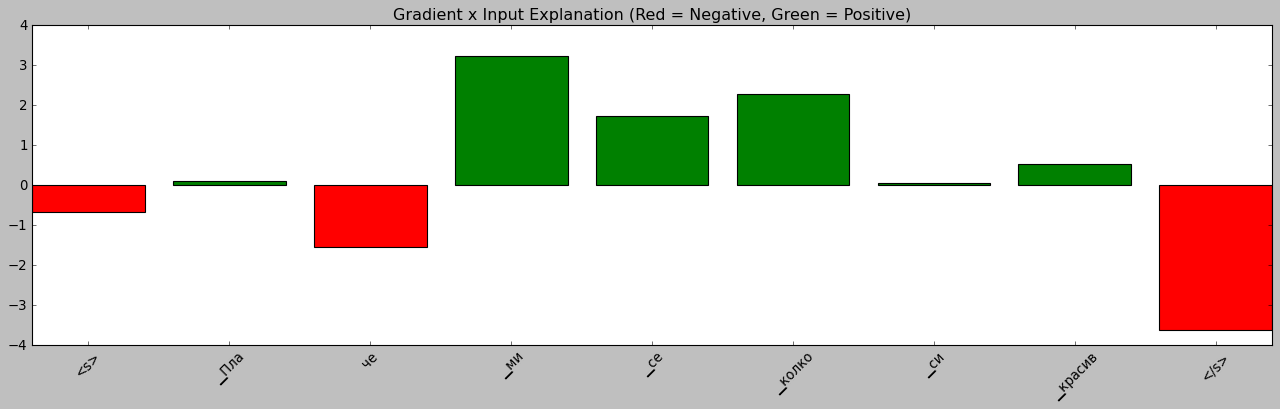

In [37]:
# Gradient x Input Explanation with Color-Coded Bars
relevance_scores = gradient_x_input(model, inputs)
tokens = tokenizer.convert_ids_to_tokens(inputs.input_ids[0])
print(inputs)
print(tokens)
# Use raw relevance scores instead of L2 norm
raw_scores = np.sum(relevance_scores[0], axis=-1)
print(raw_scores)

# Add color for positive/negative contribution based on raw values
colors = ['red' if score < 0 else 'green' for score in raw_scores]

plt.figure(figsize=(20, 5))
plt.bar(tokens, raw_scores, color=colors)
plt.title("Gradient x Input Explanation (Red = Negative, Green = Positive)")
plt.xticks(rotation=45)
plt.show()

# Direction of the label and the importances of the words

The signed Gradient × Input plot shows how each token contributes positively or negatively toward the predicted emotion. Words forming the emotional phrase ‘ми се колко си красив’ show strong positive influence, indicating that the model relies on the emotional construction of the sentence. Special tokens such as \<s> and \</s> receive high negative scores, which is common for transformer architectures where the CLS/EOS embeddings accumulate opposing gradients. The second plot displays the magnitude of contributions irrespective of direction, highlighting which tokens were the most influential overall. This confirms that the model focuses strongly on ‘ми’, ‘колко’, ‘красив’, and the emotional connectors, which aligns with the semantics of the input sentence.”


Token        | Summed Score (Direction)  | Magnitude Score (Importance)
----------------------------------------------------------------------
<s>          | -0.67346                  | 1.39726
▁Пла         | 0.08707                   | 1.57234
че           | -1.55662                  | 2.10189
▁ми          | 3.22847                   | 2.71342
▁се          | 1.71940                   | 0.83383
▁колко       | 2.26484                   | 2.22334
▁си          | 0.04757                   | 1.25971
▁красив      | 0.52342                   | 2.47774
</s>         | -3.62665                  | 2.37418
[('<s>', -0.67345977, 1.397264), ('▁Пла', 0.08707321, 1.5723443), ('че', -1.5566242, 2.101893), ('▁ми', 3.2284725, 2.7134244), ('▁се', 1.7193985, 0.8338266), ('▁колко', 2.2648413, 2.2233357), ('▁си', 0.0475747, 1.2597103), ('▁красив', 0.5234189, 2.4777386), ('</s>', -3.6266508, 2.3741848)]


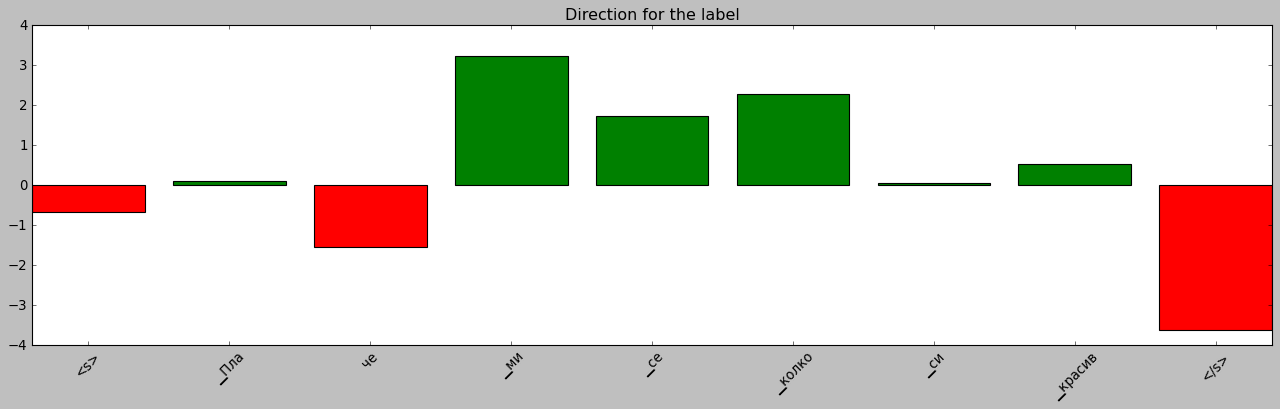

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# --- Define and tokenize your input for TensorFlow ---
text = text  # Bulgarian for "I am so happy to see you, regardless of our previous conversations."
inputs = tokenizer(text, return_tensors='tf')  # <-- Use 'tf' for TensorFlow

# --- Run the modified function ---
# relevance_scores is now a 3D NumPy array: (batch, seq_len, embed_dim)
relevance_scores = gradient_x_input(model, inputs)

tokens = tokenizer.convert_ids_to_tokens(inputs['input_ids'][0])

# Select first batch item [0], then sum/norm along the last axis (-1)
summed_scores = np.sum(relevance_scores[0], axis=-1)
magnitude_scores = np.linalg.norm(relevance_scores[0], axis=-1)

print(f"{'Token':<12} | {'Summed Score (Direction)':<25} | {'Magnitude Score (Importance)'}")
print("-" * 70)
for i, token in enumerate(tokens):
    print(
        f"{token:<12} | {summed_scores[i]:<25.5f} | {magnitude_scores[i]:.5f}")

# --- The rest of your code works perfectly as-is ---
colors = ['red' if score < 0.003 else 'green' for score in summed_scores]

words_with_scores = list(zip(tokens, summed_scores, magnitude_scores))
print(words_with_scores)

plt.figure(figsize=(20, 5))
plt.bar(tokens, summed_scores, color=colors)
plt.title("Direction for the label")
plt.xticks(rotation=45)
plt.show()

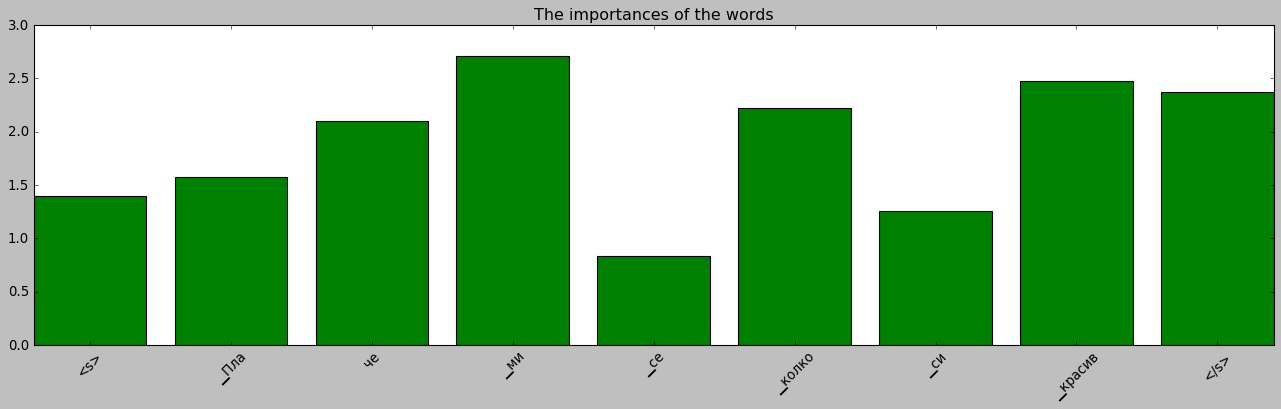

In [39]:
colors = ['red' if score < 0.3 else 'green' for score in magnitude_scores]

plt.figure(figsize=(20, 5))
plt.bar(tokens, magnitude_scores, color=colors)
plt.title("The importances of the words")
plt.xticks(rotation=45)
plt.show()

### Attention Scores

The attention scores heatmap visualizes how much each token in the input sequence influences other tokens during the model’s prediction.
Interpreting attention heatmaps in transformer models is inherently difficult, because attention is distributed across multiple layers and multiple heads. The \<s> (CLS) token in models like XLM-RoBERTa aggregates global sentence information, so many heads concentrate their attention on it. As a result, the heatmap of a single layer does not necessarily represent the model’s reasoning process. Therefore, attention heatmaps alone are not a reliable indicator of how a transformer arrives at a prediction.


In [ ]:
def gradient_x_input_SUMMED(model, inputs):  # Renamed for clarity
    """
    Calculates Gradient x Input attributions for a TF model.
    Returns the SUMMED 1D scores for each token.
    """
    embedding_layer = model.get_input_embeddings()

    with tf.GradientTape() as tape:
        inputs_embeds = embedding_layer(inputs.input_ids)
        tape.watch(inputs_embeds)

        outputs = model(
            input_ids=None,
            inputs_embeds=inputs_embeds,
            attention_mask=inputs.attention_mask
        )
        logits = outputs.logits
        predicted_class_idx = tf.argmax(logits, axis=-1)
        batch_indices = tf.range(tf.shape(predicted_class_idx)[0])
        gather_indices = tf.stack([batch_indices, tf.cast(
            predicted_class_idx, dtype=tf.int32)], axis=1)
        top_logits = tf.gather_nd(logits, gather_indices)

    gradients = tape.gradient(top_logits, inputs_embeds)
    grad_x_input = gradients * inputs_embeds

    relevance_scores = tf.reduce_sum(grad_x_input, axis=-1)
    return relevance_scores.numpy()

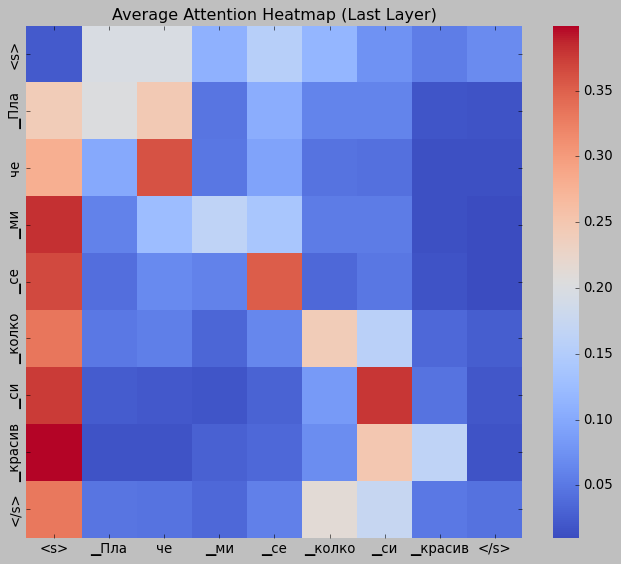

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow as tf

# Bulgarian for "I am so happy to see you, regardless of our previous conversations."
text_to_explain = text
inputs = tokenizer(text_to_explain, return_tensors="tf")
tokens = tokenizer.convert_ids_to_tokens(inputs.input_ids[0])

#    (This doesn't work in GradientTape, so we do it separately)
outputs = model(inputs, output_attentions=True)

#    Let's get the attention from the very last layer
last_layer_attention = outputs.attentions[-1]
# Shape is (batch_size, num_heads, seq_len, seq_len) -> (1, 12, 17, 17)

avg_attention = tf.reduce_mean(
    last_layer_attention[0], axis=0)  # Shape: (17, 17)

plt.figure(figsize=(10, 8))
sns.heatmap(avg_attention.numpy(), cmap='coolwarm',
            xticklabels=tokens, yticklabels=tokens)
plt.title("Average Attention Heatmap (Last Layer)")
plt.show()

### Model confidence during Token Removal

The token removal perturbation analysis demonstrates that removing the top-ranked tokens identified by Gradient × Input causes the model’s confidence to collapse below 50%, confirming that these tokens are genuinely important for the model’s prediction. The shaded area represents the point of uncertainty, where the sentence loses enough emotional context that the model becomes unreliable. This validates the correctness of the relevance scores.


Original tokens: ['<s>', '▁Пла', 'че', '▁ми', '▁се', '▁колко', '▁си', '▁красив', '</s>']
Sorted indices to perturb (by summed): [3, 5, 4, 7, 1, 6, 0, 2, 8]


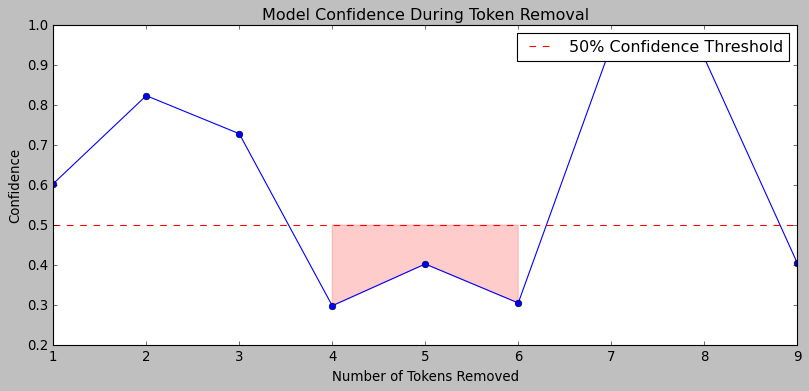

In [ ]:
# Run function
relevance_scores = gradient_x_input(model, inputs)
raw_scores = relevance_scores[0]
# print(raw_scores)
confidences_remove = perturb_input_and_evaluate(
    model, tokenizer, words_with_scores, tokens, 'summed')


# Adjust length if mismatched
min_length = min(len(tokens), len(confidences_remove))

# Convert list to numpy array
confidences_remove = np.array(confidences_remove)

plt.figure(figsize=(12, 5))
plt.plot(range(1, min_length + 1),
         confidences_remove[:min_length], marker='o', color='blue')
plt.axhline(y=0.5, color='red', linestyle='--',
            label="50% Confidence Threshold")
plt.fill_between(
    range(1, min_length + 1),
    confidences_remove[:min_length],
    0.5,
    where=(confidences_remove[:min_length] < 0.5),
    color='red',
    alpha=0.2
)
plt.title("Model Confidence During Token Removal")
plt.xlabel("Number of Tokens Removed")
plt.ylabel("Confidence")
plt.legend()
plt.show()

### LIME

The LIME visualization decomposes the model’s prediction by evaluating how local perturbations of the input affect output probabilities. For the sentence ‘Плаче ми се колко си красив’(I'm crying because you're so beautiful.), the model strongly predicts sadness (87%). LIME identifies ‘Плаче’(crying) as the primary contributor to this prediction, with secondary contributions from ‘колко’(how much) and ‘красив’(beatiful), which appear in emotional contexts. The bottom panel highlights these influential tokens within the original text. This confirms that the model is relying on semantically meaningful words rather than spurious artifacts.

LIME (Local Interpretable Model-Agnostic Explanations) explains one specific prediction by approximating the model locally with a simple linear model.
This visualization shows:

- the model’s probability distribution
- the contribution of each token to each class
- highlighted words in the original text


In [ ]:
import tensorflow as tf
import numpy as np

# Define the predictor function for LIME using TensorFlow


def predictor(texts):
    """
    Converts raw text strings into a NumPy array of probabilities
    using the TensorFlow model.
    """

    # 1. Tokenize the texts for TensorFlow
    inputs = tokenizer(
        texts,
        return_tensors="tf",  # <-- Use 'tf' instead of 'pt'
        padding=True,
        truncation=True
    )

    # 2. Get model outputs (no .to("cpu") or torch.no_grad() needed)
    outputs = model(inputs)

    # 3. Convert logits to probabilities using TensorFlow's softmax
    # LIME expects probabilities, not logits
    probabilities = tf.nn.softmax(outputs.logits, axis=-1)

    # 4. Return as a NumPy array (which LIME expects)
    return probabilities.numpy()

In [ ]:
from lime.lime_text import LimeTextExplainer


def analyse_with_Lime(class_names, text):
    plt.style.use('classic')

    explainer = LimeTextExplainer(class_names=class_names)
    exp = explainer.explain_instance(
        text, predictor, num_features=10, labels=range(len(class_names)))
    return exp

In [45]:
explanation = analyse_with_Lime(labels, text)

explanation.show_in_notebook(text=True)

### About the visualization

Here’s the interpretation in human terms:
The word “Плаче”(Crying) is by far the strongest indicator of sadness.
The words “колко си красив” ("how beautiful you are") surprisingly also contribute slightly toward sadness.

This is because the sentence can be interpreted as crying from overwhelming beauty → emotional sadness.
Words like “ми” and “се” provide additional emotional structure but are weaker.
No strong indicators of happiness, disgust, fear, anger, or surprise are present.

So the LIME visualization is telling you:

    The model predicts sadness, and the reasoning is mostly driven by the presence of the verb "crying."
